# Our drone's INS, measured (COH-21 / COH-33)

A 37-minute static log of the X500's Pixhawk 6C, sitting still indoors. This notebook turns it into the
`x500_measured` IMU grade in `ins/errors.py`, replacing the guessed biases.

First, from `modelling/`: `unzip `../hardware/flight_logs/2026-10-15_static_imu_test.bin.zip`, then `python scripts/extract_ardupilot_log.py ../hardware/flight_logs/2026-10-15_static_imu_test.bin`

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ins import GRADES, ErrorModel, lawnmower, synthetic_flight, run_ins
from ins.allan import allan_deviation, fit_allan

LOG = pathlib.Path("../data/ardupilot/2026-10-15_static_imu_test")
IMU_ID = 0                      # 0 is the one the EKF uses; try 1 for the second IMU
imu = pd.read_csv(LOG / "IMU.csv").query("I == @IMU_ID").reset_index(drop=True)
ekf = pd.read_csv(LOG / "XKF1.csv").query("C == @IMU_ID")
rate = 1 / np.median(np.diff(imu.time_s))
print(f"IMU{IMU_ID}: {len(imu)} samples at {rate:.0f} Hz over {imu.time_s.iloc[-1] / 60:.0f} min")

IMU0: 880562 samples at 399 Hz over 37 min


## 1. Warm-up: the heater, and a bias the EKF learns

The board heater takes the IMU from room temperature to 45 °C. The gyros were calibrated at boot,
when they were cold, so the bias moves while it heats up and then settles. The dashed line is
the EKF's own estimate of that bias.

steady part: 33 min at 44.9 °C


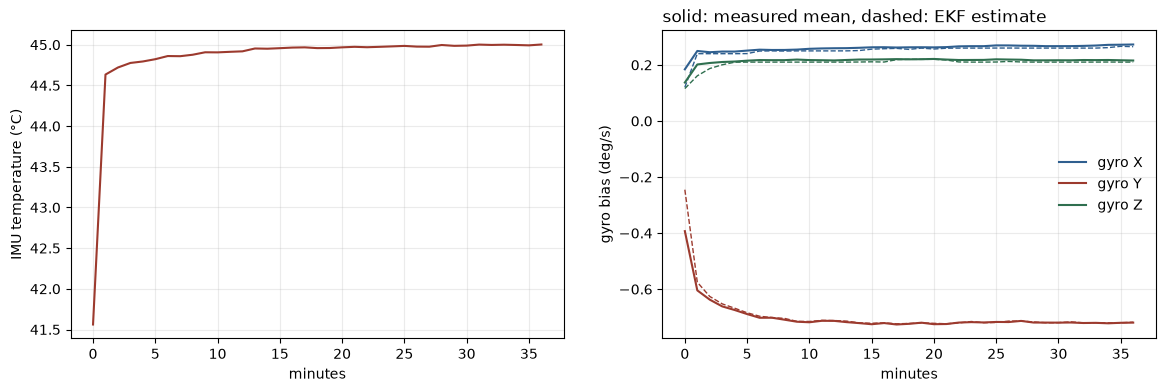

In [2]:
per_min = imu.assign(minute=(imu.time_s // 60)).groupby("minute").mean()
ekf_min = ekf.assign(minute=(ekf.time_s // 60)).groupby("minute").mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(per_min.index, per_min["T"], color="#9c3a2e"); ax[0].set_ylabel("IMU temperature (°C)")
for axis, c in zip("XYZ", ["#2f5f8f", "#9c3a2e", "#2f6f4f"]):
    ax[1].plot(per_min.index, np.degrees(per_min[f"Gyr{axis}"]), color=c, label=f"gyro {axis}")
    ax[1].plot(ekf_min.index, ekf_min[f"G{axis}"], "--", color=c, lw=1)
ax[1].set_ylabel("gyro bias (deg/s)"); ax[1].legend(frameon=False)
for a in ax: a.set_xlabel("minutes"); a.grid(alpha=0.25)
ax[1].set_title("solid: measured mean, dashed: EKF estimate", loc="left")

STEADY_FROM_S = 240     # after the heater has settled
steady = imu[imu.time_s > STEADY_FROM_S]
print(f"steady part: {len(steady) / rate / 60:.0f} min at {steady['T'].mean():.1f} °C")

## 2. Allan deviation: noise and bias wander

Each error shows up as its own slope on this plot. The **left side** (slope −½) is white noise, and its
value at 1 s is the noise density. The **bottom** is bias instability. A **rise on the right** is the bias
wandering. The dotted lines are the datasheet noise.

,noise /rtHz,bias instability,at tau (s),bias RW /rts
"deg/s (gyro), ug (accel)",,,,
GyrX,0.00547,0.00174,46.71685,0.00024
GyrY,0.01410,0.00456,38.52474,0.00062
GyrZ,0.00397,0.00140,46.71685,0.00016
AccX,97.42004,21.45633,148.55568,NaN
AccY,90.02324,38.39305,17.81515,6.61031
AccZ,255.80111,115.96875,21.60423,22.76722


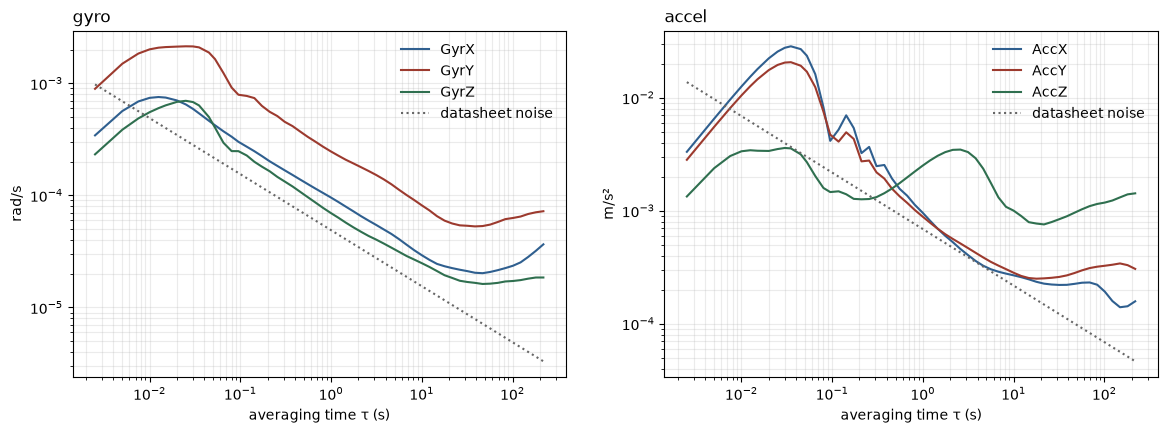

In [3]:
DATASHEET = {"gyro": np.radians(0.0028), "accel": 70e-6 * 9.80665}      # per rtHz
fits = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k, (sensor, cols) in enumerate({"gyro": ["GyrX", "GyrY", "GyrZ"],
                                     "accel": ["AccX", "AccY", "AccZ"]}.items()):
    for col, c in zip(cols, ["#2f5f8f", "#9c3a2e", "#2f6f4f"]):
        taus, adev = allan_deviation(steady[col].to_numpy(), rate)
        fits[col] = fit_allan(taus, adev)
        ax[k].loglog(taus, adev, color=c, label=col)
    ax[k].loglog(taus, DATASHEET[sensor] / np.sqrt(taus), ":", color="0.4", label="datasheet noise")
    ax[k].set_xlabel("averaging time τ (s)"); ax[k].grid(alpha=0.25, which="both")
    ax[k].set_ylabel("rad/s" if sensor == "gyro" else "m/s²"); ax[k].legend(frameon=False)
    ax[k].set_title(sensor, loc="left")

to_unit = lambda col, v: np.degrees(v) if col.startswith("Gyr") else v / 9.80665 * 1e6
pd.DataFrame({col: {"noise /rtHz": to_unit(col, f.noise_density),
                    "bias instability": to_unit(col, f.bias_instability),
                    "at tau (s)": f.instability_tau_s,
                    "bias RW /rts": to_unit(col, f.bias_rw)} for col, f in fits.items()}
             ).T.round(5).rename_axis("deg/s (gyro), ug (accel)")

## 3. The bias that's left after the EKF

What matters after a GNSS cut is the bias the EKF *hasn't* already removed: the raw mean minus the EKF's
estimate. That residual includes the Earth's rotation (up to 0.004 °/s here), so it's an upper bound.

In [4]:
rows = {}
for w0 in (300, 900, 1500, 1800):
    raw = imu[(imu.time_s > w0) & (imu.time_s < w0 + 300)]
    est = ekf[(ekf.time_s > w0) & (ekf.time_s < w0 + 300)]
    rows[f"{w0 // 60}-{(w0 + 300) // 60} min"] = {
        a: np.degrees(raw[f"Gyr{a}"].mean()) - est[f"G{a}"].mean() for a in "XYZ"}
pd.DataFrame(rows).T.round(4).rename_axis("residual gyro bias, deg/s")

,X,Y,Z
"residual gyro bias, deg/s",,,
5-10 min,0.0055,-0.0033,0.0071
15-20 min,0.0051,-0.0015,0.0041
25-30 min,0.0085,-0.0005,0.0074
30-35 min,0.0082,-0.0010,0.0070


## 4. What this does to drift

The same 20-minute survey flown with the old guessed numbers (`consumer_mems`), our measured INS, and
a tactical-grade unit for scale. The last line is a what-if: losing GNSS **before** the EKF has learnt the
bias (for example straight after boot), when the full 0.7 °/s is still there.

consumer_mems                   1 min       463 m     5 min     55026 m    10 min    228181 m   


x500_measured                   1 min        35 m     5 min      5366 m    10 min     31322 m   


tactical                        1 min        12 m     5 min       133 m    10 min      1155 m   


x500, before EKF learns bias    1 min      4260 m     5 min    180754 m    10 min    641240 m   


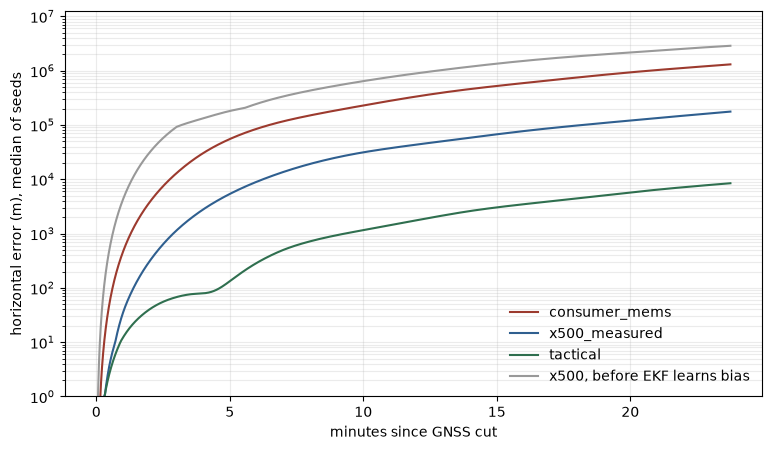

In [5]:
before_ekf = ErrorModel(**{**GRADES["x500_measured"].__dict__,
                           "gyro_turnon_bias": np.radians(0.45), "name": "x500, before EKF learns bias"})
truth, perfect = synthetic_flight(lawnmower((52.45, -6.40), 1500, 900, 150), alt_m=60, speed_mps=8)
SEEDS = range(3)

plt.figure(figsize=(9, 5))
for grade, c in [(GRADES["consumer_mems"], "#9c3a2e"), (GRADES["x500_measured"], "#2f5f8f"),
                 (GRADES["tactical"], "#2f6f4f"), (before_ekf, "0.6")]:
    runs = [run_ins(perfect, truth, grade=grade, seed=s) for s in SEEDS]
    err = np.median([r.error_m for r in runs], axis=0)
    plt.semilogy(runs[0].elapsed_s / 60, err, color=c, label=grade.name)
    print(f"{grade.name:30s}" + "".join(f"{m:3d} min {np.interp(m * 60, runs[0].elapsed_s, err):9.0f} m   "
                                         for m in (1, 5, 10)))
plt.xlabel("minutes since GNSS cut"); plt.ylabel("horizontal error (m), median of seeds")
plt.legend(frameon=False); plt.grid(alpha=0.25, which="both"); plt.ylim(1, None);

## 5. The filter, with our INS

The same particle filter as `particle_filter.ipynb`, over Co. Mayo, now using the measured grade.

consumer_mems, 10.1 min after the cut
            INS only  INS+MagNav  PF 2sigma
    1 min      173.3       127.0      499.0  m
    5 min    11551.0      1197.5     1248.0  m
   10 min    46018.2      2526.0     3906.6  m
   20 min       -           -          -     m

x500_measured, 10.1 min after the cut
            INS only  INS+MagNav  PF 2sigma
    1 min       29.1        27.1      120.7  m
    5 min     2753.5      1062.7     1040.7  m
   10 min    12223.8        86.6      601.2  m
   20 min       -           -          -     m



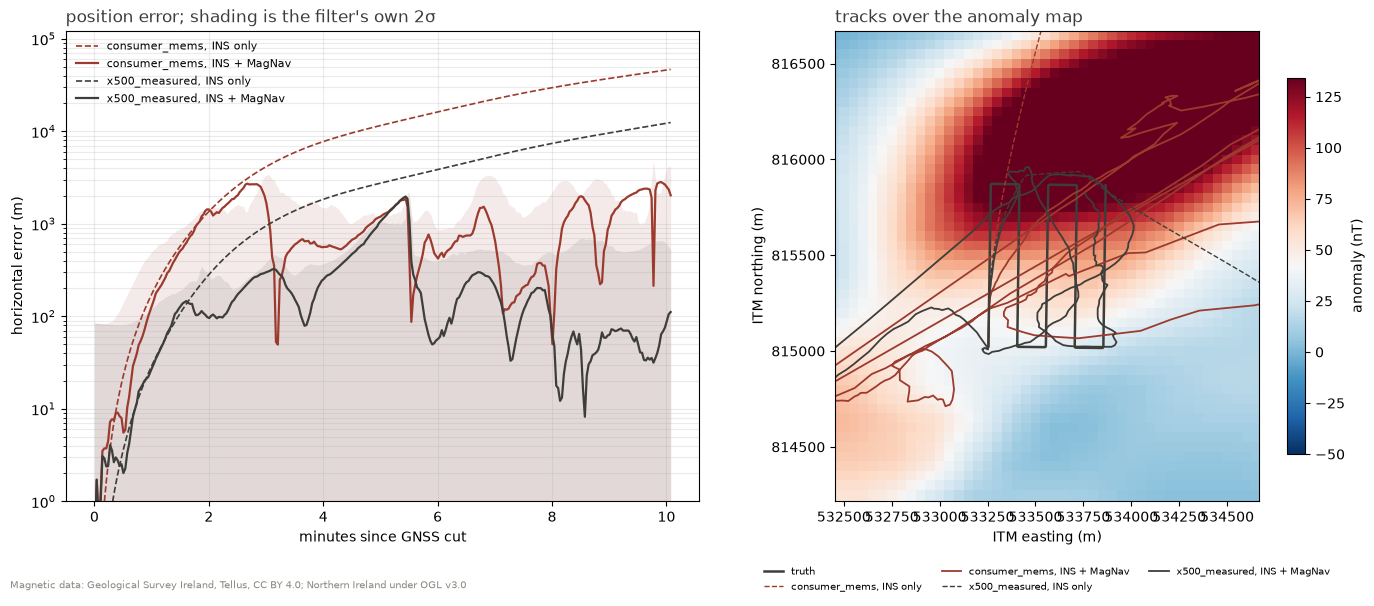

In [6]:
from navfilter import scenario
sim = scenario.simulate(54.08, -9.02, minutes=10, grades=["consumer_mems", "x500_measured"])
sim.summary()
scenario.plot(sim.runs, sim.filter_map, sim.truth);

## Next acquisition, to tighten these numbers

1. **Several short power-ups (5 × 10 min) rather than one long one.** Turn-on bias changes every boot, and one log gives one value, not the spread.
2. **Turn on temperature calibration** (`INS_TCAL1_ENABLE`), or log a slow cold-to-hot warm-up, so the 0.7 °/s heater drift is calibrated out instead of learnt by the EKF.
3. **Outdoors with GPS, pointing north.** Then the Earth's rotation can be separated from the residual bias, and the EKF has GPS like it would in flight.
4. **Motors spinning, props off, tied down,** to see how much vibration adds to the noise. The y gyro is already 5× the datasheet.